# Water Quality Patterns, Correlations and Target Behavior


# Setup and Data Loading


In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH = "data/Dataset/Parquet/Combined Data/Combined_dataset.parquet"
OUT_DIR = "data/GeneratedOutput/01.EDA"
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("..", "..", DATA_PATH)
    OUT_DIR = os.path.join("..", "..", OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_parquet(DATA_PATH)
chemical_cols = [
    "Ammonia (mg/l)", "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)", "Orthophosphate (mg/l)",
    "pH (ph units)", "Temperature (cel)", "Nitrogen (mg/l)", "Nitrate (mg/l)"
]
print(df.shape)


(4297895, 14)


# Sentinel and Physical Bounds Audit


In [11]:
sentinel_records = []
for col in chemical_cols:
    s = df[col].dropna()
    sentinel_records.append({
        "Feature": col,
        "Count < -100": int((s < -100).sum()),
        "Min Value": float(s.min()),
        "Max Value": float(s.max())
    })
sentinel_df = pd.DataFrame(sentinel_records)
print(sentinel_df)
ph_corrupt = df[(df["pH (ph units)"] > 14) | (df["pH (ph units)"] < 0)]
print("Physically impossible pH rows:", len(ph_corrupt))


                            Feature  Count < -100   Min Value  Max Value
0                    Ammonia (mg/l)             0      -0.005     200.00
1  Biochemical Oxygen Demand (mg/l)             0      -2.000     534.50
2           Dissolved Oxygen (mg/l)             1 -999999.000      23.75
3             Orthophosphate (mg/l)             0      -0.004     100.00
4                     pH (ph units)             3 -999999.000   67115.00
5                 Temperature (cel)            81 -999999.000      98.00
6                   Nitrogen (mg/l)             0       0.000      46.00
7                    Nitrate (mg/l)             0       0.000     790.02
Physically impossible pH rows: 597


# Dissolved Oxygen vs Temperature Saturation


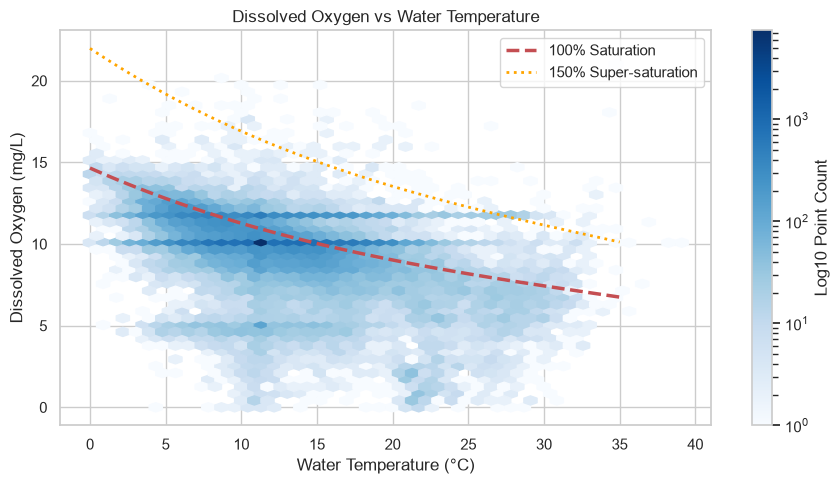

In [12]:
sample_df = df.dropna(subset=["Temperature (cel)", "Dissolved Oxygen (mg/l)"])
sample_clean = sample_df[
    (sample_df["Temperature (cel)"] >= 0) & (sample_df["Temperature (cel)"] <= 40) &
    (sample_df["Dissolved Oxygen (mg/l)"] >= 0) & (sample_df["Dissolved Oxygen (mg/l)"] <= 30)
].sample(50000, random_state=42)

t_curve = np.linspace(0, 35, 100)
do_sat_curve = 14.652 - 0.41022 * t_curve + 0.007991 * (t_curve**2) - 0.000077774 * (t_curve**3)

plt.figure(figsize=(9, 5))
plt.hexbin(sample_clean["Temperature (cel)"], sample_clean["Dissolved Oxygen (mg/l)"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
plt.plot(t_curve, do_sat_curve, "r--", lw=2.5, label="100% Saturation")
plt.plot(t_curve, do_sat_curve * 1.5, "orange", linestyle=":", lw=2, label="150% Super-saturation")
plt.title("Dissolved Oxygen vs Water Temperature")
plt.xlabel("Water Temperature (°C)")
plt.ylabel("Dissolved Oxygen (mg/L)")
plt.colorbar(label="Log10 Point Count")
plt.legend()
plt.tight_layout()
plt.show()


# Outlier Statistics Using IQR Bounds


In [13]:
outlier_stats = []
for col in chemical_cols:
    s = df[col].dropna()
    s_valid = s[(s >= -10) & (s <= 10000)]
    q25, q75 = s_valid.quantile(0.25), s_valid.quantile(0.75)
    iqr = q75 - q25
    upper_soft = q75 + 1.5 * iqr
    upper_hard = q75 + 3.0 * iqr
    outlier_stats.append({
        "Feature": col,
        "Median": round(s_valid.median(), 3),
        "IQR": round(iqr, 3),
        "Soft Bound": round(upper_soft, 3),
        "Soft Outliers (%)": round((s_valid > upper_soft).mean() * 100, 2),
        "Hard Bound": round(upper_hard, 3),
        "Hard Outliers (%)": round((s_valid > upper_hard).mean() * 100, 2)
    })
outlier_df = pd.DataFrame(outlier_stats)
print(outlier_df)


                            Feature  Median    IQR  Soft Bound  \
0                    Ammonia (mg/l)   0.055  0.287       0.748   
1  Biochemical Oxygen Demand (mg/l)   2.700  1.230       4.675   
2           Dissolved Oxygen (mg/l)  10.200  1.510      13.165   
3             Orthophosphate (mg/l)   0.107  0.187       0.507   
4                     pH (ph units)   7.780  0.490       8.735   
5                 Temperature (cel)  11.900  7.900      29.050   
6                   Nitrogen (mg/l)   4.000  5.540      14.630   
7                    Nitrate (mg/l)   4.500  3.770      10.595   

   Soft Outliers (%)  Hard Bound  Hard Outliers (%)  
0              14.31       1.178              11.49  
1              14.61       6.520              10.44  
2               1.64      15.430               0.22  
3              16.62       0.788              13.89  
4               0.99       9.470               0.17  
5               3.07      40.900               0.17  
6               7.65      2

# Pearson and Spearman Feature Correlation Heatmaps


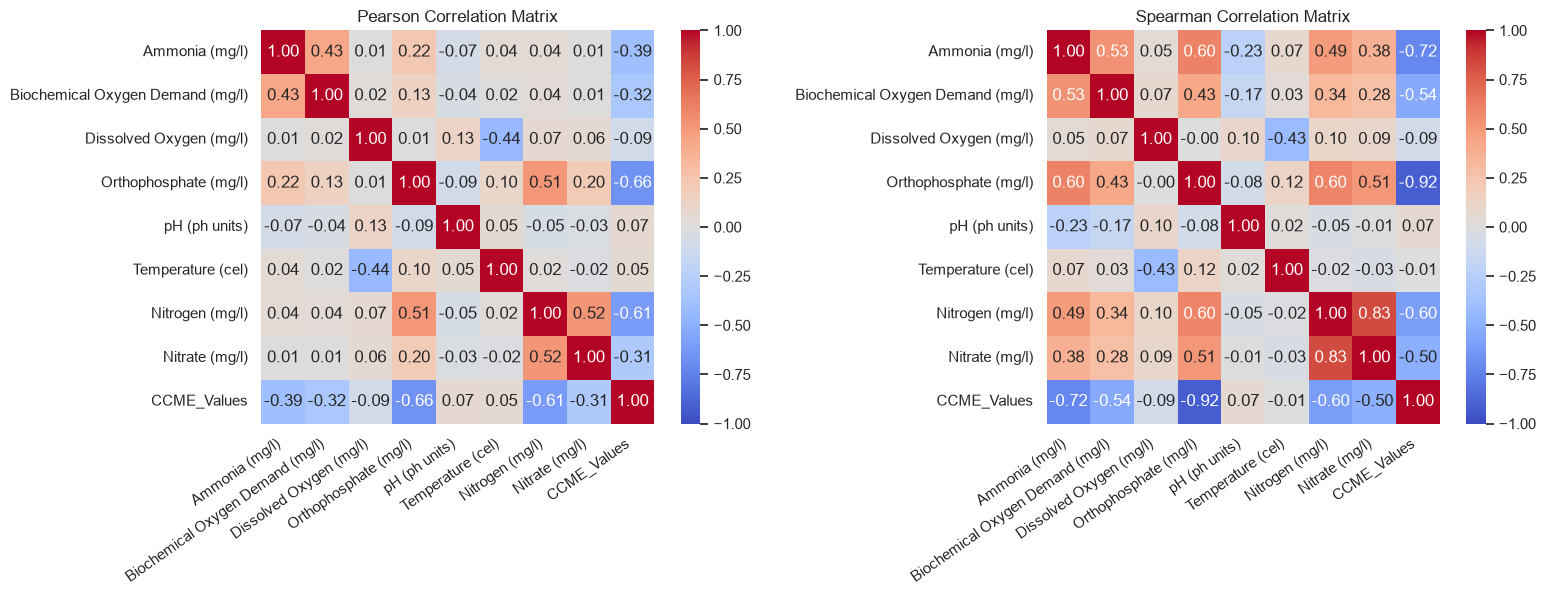

In [14]:
df_phys_clean = df[
    (df["pH (ph units)"].isna() | ((df["pH (ph units)"] >= 3) & (df["pH (ph units)"] <= 12))) &
    (df["Temperature (cel)"].isna() | ((df["Temperature (cel)"] >= 0) & (df["Temperature (cel)"] <= 45))) &
    (df["Dissolved Oxygen (mg/l)"].isna() | ((df["Dissolved Oxygen (mg/l)"] >= 0) & (df["Dissolved Oxygen (mg/l)"] <= 25)))
].copy()

analysis_cols = chemical_cols + ["CCME_Values"]
pearson_corr = df_phys_clean[analysis_cols].corr(method="pearson")
spearman_corr = df_phys_clean[analysis_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Pearson Correlation Matrix")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=35, ha="right")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title("Spearman Correlation Matrix")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Nutrient Ratios and Oxygen Dynamics


Median N:P Ratio: 26.09


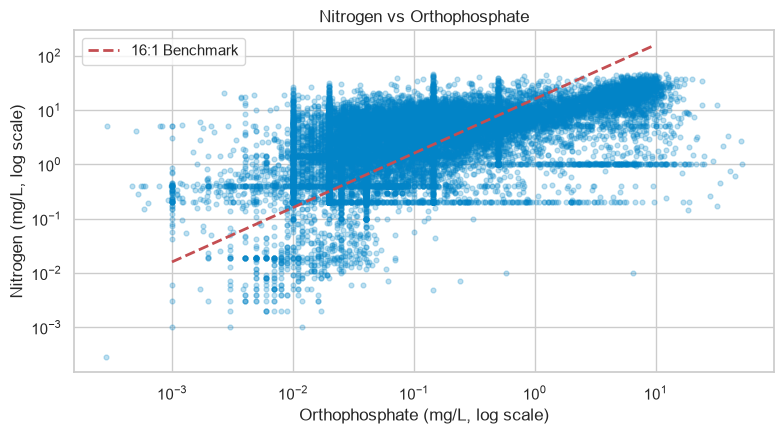

In [15]:
np_df = df_phys_clean.dropna(subset=["Nitrogen (mg/l)", "Orthophosphate (mg/l)"]).copy()
np_df = np_df[(np_df["Nitrogen (mg/l)"] > 0) & (np_df["Orthophosphate (mg/l)"] > 0)]
np_df["NP_Ratio"] = np_df["Nitrogen (mg/l)"] / np_df["Orthophosphate (mg/l)"]
print("Median N:P Ratio:", round(float(np_df["NP_Ratio"].median()), 2))

sample_np = np_df.sample(25000, random_state=42)
plt.figure(figsize=(8, 4.5))
plt.scatter(sample_np["Orthophosphate (mg/l)"], sample_np["Nitrogen (mg/l)"], alpha=0.25, s=12, c="#0284c7")
p_vals = np.linspace(0.001, sample_np["Orthophosphate (mg/l)"].quantile(0.99), 100)
plt.plot(p_vals, p_vals * 16, "r--", lw=2, label="16:1 Benchmark")
plt.xscale("log")
plt.yscale("log")
plt.title("Nitrogen vs Orthophosphate")
plt.xlabel("Orthophosphate (mg/L, log scale)")
plt.ylabel("Nitrogen (mg/L, log scale)")
plt.legend()
plt.tight_layout()
plt.show()


# Monthly Seasonality Patterns


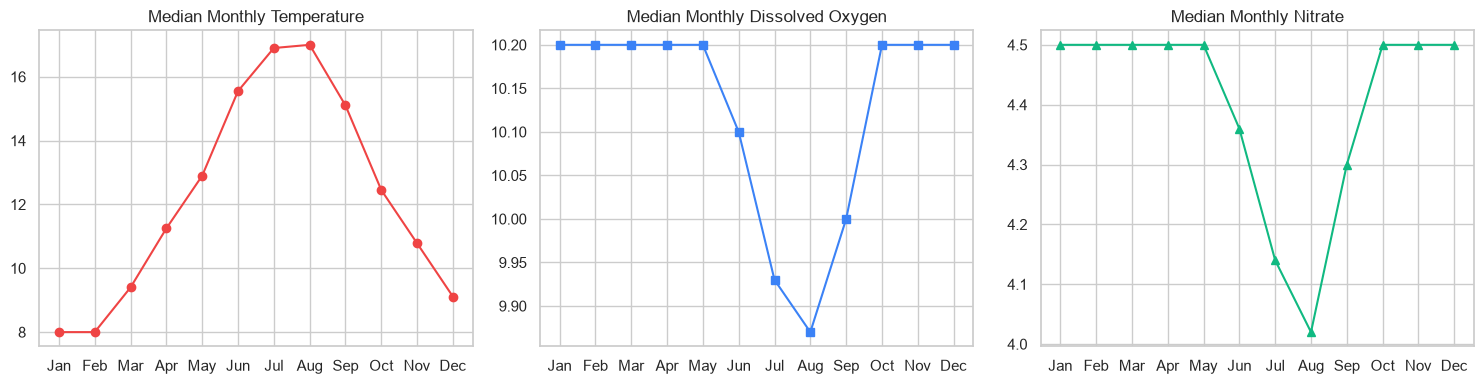

In [16]:
df["Month"] = df["Date"].str.split("-").str[1].astype(int)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_chem = df.groupby("Month")[["Temperature (cel)", "Dissolved Oxygen (mg/l)", "Nitrate (mg/l)"]].median()
monthly_chem.index = [month_names[m - 1] for m in monthly_chem.index]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(monthly_chem.index, monthly_chem["Temperature (cel)"], marker="o", color="#ef4444")
axes[0].set_title("Median Monthly Temperature")
axes[1].plot(monthly_chem.index, monthly_chem["Dissolved Oxygen (mg/l)"], marker="s", color="#3b82f6")
axes[1].set_title("Median Monthly Dissolved Oxygen")
axes[2].plot(monthly_chem.index, monthly_chem["Nitrate (mg/l)"], marker="^", color="#10b981")
axes[2].set_title("Median Monthly Nitrate")
plt.tight_layout()
plt.show()


# Target Score Distribution and Classification Categories


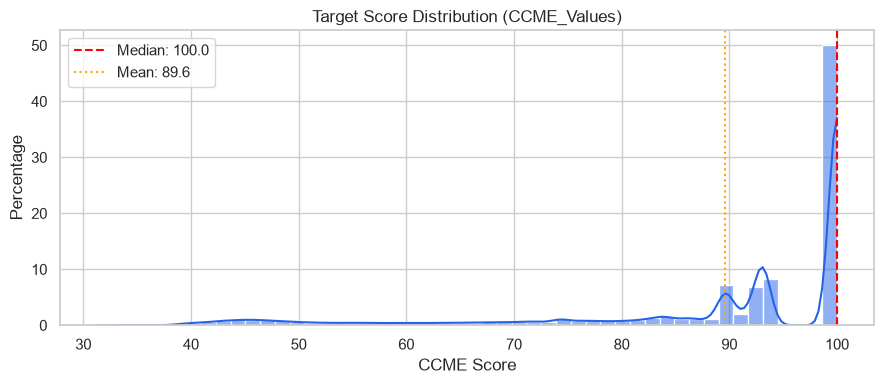

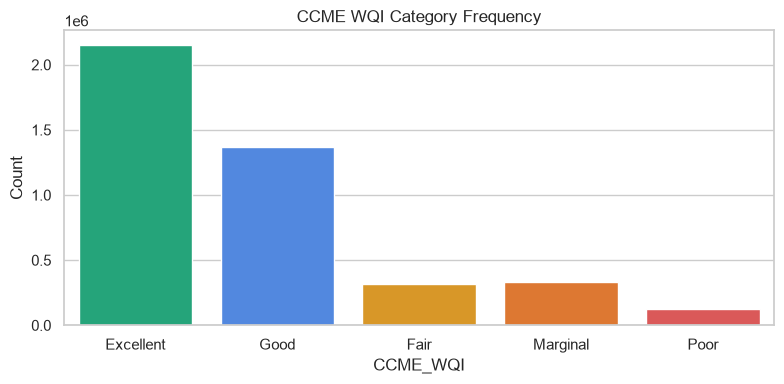

In [17]:
median_val = float(df["CCME_Values"].median())
mean_val = float(df["CCME_Values"].mean())
plt.figure(figsize=(9, 4))
sns.histplot(df["CCME_Values"], bins=50, kde=True, color="#2563eb", stat="percent")
plt.axvline(median_val, color="red", linestyle="--", label=f"Median: {median_val:.1f}")
plt.axvline(mean_val, color="orange", linestyle=":", label=f"Mean: {mean_val:.1f}")
plt.title("Target Score Distribution (CCME_Values)")
plt.xlabel("CCME Score")
plt.ylabel("Percentage")
plt.legend()
plt.tight_layout()
plt.show()

order = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
wqi_counts = df["CCME_WQI"].value_counts().reindex(order)
plt.figure(figsize=(8, 4))
sns.barplot(x=wqi_counts.index, y=wqi_counts.values, palette=["#10b981", "#3b82f6", "#f59e0b", "#f97316", "#ef4444"], hue=wqi_counts.index, legend=False)
plt.title("CCME WQI Category Frequency")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# Filter Physically Valid Data and Export Summaries


In [18]:
valid_mask = (
    (df["pH (ph units)"].isna() | ((df["pH (ph units)"] >= 3.0) & (df["pH (ph units)"] <= 12.0))) &
    (df["Temperature (cel)"].isna() | ((df["Temperature (cel)"] >= -2.0) & (df["Temperature (cel)"] <= 50.0))) &
    (df["Dissolved Oxygen (mg/l)"].isna() | ((df["Dissolved Oxygen (mg/l)"] >= 0.0) & (df["Dissolved Oxygen (mg/l)"] <= 30.0))) &
    (df["Ammonia (mg/l)"].isna() | (df["Ammonia (mg/l)"] >= 0.0)) &
    (df["Biochemical Oxygen Demand (mg/l)"].isna() | (df["Biochemical Oxygen Demand (mg/l)"] >= 0.0)) &
    (df["Orthophosphate (mg/l)"].isna() | (df["Orthophosphate (mg/l)"] >= 0.0))
)
cleaned_df = df[valid_mask][[
    "Country", "Area", "Waterbody Type", "Date",
    "Ammonia (mg/l)", "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)", "Orthophosphate (mg/l)",
    "pH (ph units)", "Temperature (cel)", "Nitrogen (mg/l)", "Nitrate (mg/l)",
    "CCME_Values", "CCME_WQI"
]].copy()
removed_count = len(df) - len(cleaned_df)
print(f"Removed {removed_count} corrupt rows. Retained {len(cleaned_df)} rows.")

p3_path = os.path.join(OUT_DIR, "03_cleaned_physically_validated.parquet")
pd.DataFrame({
    "Metric": ["Total Input Rows", "Corrupt Sentinels Removed", "Valid Clean Rows", "Removal Percentage"],
    "Value": [f"{len(df):,}", f"{removed_count:,}", f"{len(cleaned_df):,}", f"{removed_count/len(df)*100:.3f}%"]
}).to_parquet(p3_path, index=False, compression="snappy")

p4_path = os.path.join(OUT_DIR, "04_feature_correlations.parquet")
spearman_corr.reset_index().to_parquet(p4_path, index=False, compression="snappy")

p5_path = os.path.join(OUT_DIR, "05_temporal_spatial_aggregates.parquet")
monthly_chem.reset_index().to_parquet(p5_path, index=False, compression="snappy")

min_val = float(df["CCME_Values"].min())
max_val = float(df["CCME_Values"].max())
wqi_pct = df["CCME_WQI"].value_counts(normalize=True) * 100
p6_path = os.path.join(OUT_DIR, "06_target_distributions_and_leakage_audit.parquet")
pd.DataFrame({
    "Metric": ["CCME_Values (Min)", "CCME_Values (Median)", "CCME_Values (Mean)", "CCME_Values (Max)",
               "CCME_WQI (Excellent)", "CCME_WQI (Good)", "CCME_WQI (Fair)", "CCME_WQI (Marginal)", "CCME_WQI (Poor)",
               "Leakage Risk"],
    "Value / Frequency": [f"{min_val:.1f}", f"{median_val:.1f}", f"{mean_val:.1f}", f"{max_val:.1f}",
                         f"{wqi_counts.get('Excellent', 0):,} ({wqi_pct.get('Excellent', 0):.1f}%)",
                         f"{wqi_counts.get('Good', 0):,} ({wqi_pct.get('Good', 0):.1f}%)",
                         f"{wqi_counts.get('Fair', 0):,} ({wqi_pct.get('Fair', 0):.1f}%)",
                         f"{wqi_counts.get('Marginal', 0):,} ({wqi_pct.get('Marginal', 0):.1f}%)",
                         f"{wqi_counts.get('Poor', 0):,} ({wqi_pct.get('Poor', 0):.1f}%)",
                         "Algebraic leakage if evaluated without data separation"]
}).to_parquet(p6_path, index=False, compression="snappy")

final_path = os.path.join(OUT_DIR, "final_eda_cleaned_dataset.parquet")
cleaned_df.to_parquet(final_path, index=False, compression="snappy")
print("All summary and cleaned parquet files successfully exported.")


Removed 7822 corrupt rows. Retained 4290073 rows.
All summary and cleaned parquet files successfully exported.
